# Etapa 4 — MLE, MAP, Naive Bayes e EM robusto

Trata explicitamente a massa em zero; Z representa regimes latentes **entre contagens positivas** do mês anterior. A classe Z=0 indica um zero observado.

**Fonte:** BancoVDE 2026.xlsx / MJSP. **Semente:** 42.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_root():
    """Localiza a raiz do projeto (pasta com scripts/utils.py e data/) a partir do diretório atual."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "scripts" / "utils.py").exists() and (base / "data").exists():
            return base
    for pattern in ("*/scripts/utils.py", "*/*/scripts/utils.py"):   # ex.: Colab em /content
        for hit in sorted(here.glob(pattern)):
            if (hit.parent.parent / "data").exists():
                return hit.parent.parent
    raise FileNotFoundError(
        "Raiz do projeto não encontrada: abra o notebook com o diretório atual "
        "dentro da pasta FIA_P3_SegurancaPublica_Equipe5."
    )

ROOT = _find_root()

sys.path.insert(0, str(ROOT / "scripts"))
sys.modules.pop("utils", None)

from utils import (
    panel,
    training_split,
    prepare_splits,
    temporal_split,
    write_metrics
)

np.random.seed(42)

(ROOT / "outputs").mkdir(exist_ok=True)

print("Configuração da Etapa 4 concluída!")

Configuração da Etapa 4 concluída!


In [2]:
from em import (
    bernoulli_mle,
    bernoulli_map,
    bernoulli_posterior_mean,
    CategoricalNB,
    hurdle_em,
    hurdle_posterior
)

from utils import class_features
from sklearn.metrics import accuracy_score, classification_report

p, tr, te, _ = training_split()

x = tr.alto.to_numpy(int)

print("MLE:", bernoulli_mle(x))
print("MAP - moda Beta(2,2):", bernoulli_map(x))
print("Média posterior:", bernoulli_posterior_mean(x))

MLE: 0.22442084942084942
MAP - moda Beta(2,2): 0.22468659594985535
Média posterior: 0.22495183044315992


## Naive Bayes categórico do zero
As probabilidades condicionais usam suavização de Laplace, com uma categoria explícita para valores não observados no treino; a comparação mantém a mesma divisão que as etapas de classificação.

In [3]:
Xtr = class_features(tr)
Xte = class_features(te)

nb = CategoricalNB().fit(
    Xtr,
    tr.alto.to_numpy()
)

yp = nb.predict(Xte)

acc = accuracy_score(te.alto, yp)

print("Naive Bayes puro:", acc)

print(
    classification_report(
        te.alto,
        yp,
        zero_division=0
    )
)

Naive Bayes puro: 0.8706563706563707
              precision    recall  f1-score   support

           0       0.97      0.87      0.91       413
           1       0.63      0.88      0.73       105

    accuracy                           0.87       518
   macro avg       0.80      0.87      0.82       518
weighted avg       0.90      0.87      0.88       518



## A degeneração de gaussianas e a solução hurdle
Uma normal ajustada a observações coincidentes pode aumentar indefinidamente sua densidade local quando a variância tende a zero. A massa $P(lag1=0)$ é estimada separadamente e duas normais são ajustadas apenas para $\log(1+lag1)>0$, com variância inferior limitada a 0,05. O E-step calcula responsabilidades usando **peso, média e variância**. O M-step reestima esses parâmetros, e a log-verossimilhança é conferida a cada iteração.

Zeros treino: 0.1969111969111969 médias: [1.10581996 3.94454588] variâncias: [0.14105073 2.14268721] pesos: [0.17027541 0.82972459]
Iterações: 132 LL inicial/final: -3242.7419804463207 -3147.7055764081615 monotônica? True
NB puro: 0.8706563706563707 NB+EM: 0.8764478764478765 diferença: 0.00579150579150578
McNemar exato (pareado): 11 ganhos, 8 perdas; p = 0.6476058959960938


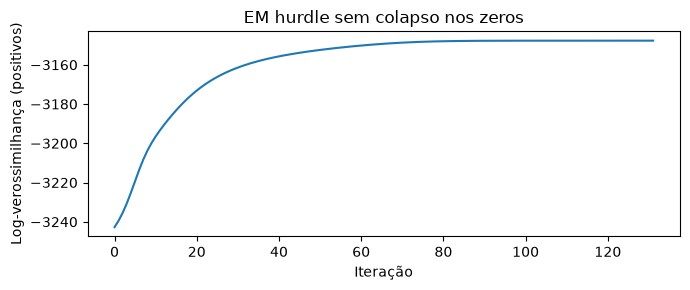

PosixPath('FIA_P3_SegurancaPublica_Equipe5/outputs/etapa4.json')

In [4]:
from scipy.stats import binomtest

model = hurdle_em(
    tr.lag1,
    variance_floor=0.05,
    tol=1e-5
)

post_tr = hurdle_posterior(tr.lag1, model)
post_te = hurdle_posterior(te.lag1, model)

ztr = np.argmax(post_tr, axis=1)
zte = np.argmax(post_te, axis=1)

xt = Xtr.copy()
xe = Xte.copy()

xt["regime_em"] = ztr.astype(str)
xe["regime_em"] = zte.astype(str)

nb_em = CategoricalNB().fit(
    xt,
    tr.alto.to_numpy()
)

pred2 = nb_em.predict(xe)
acc2 = accuracy_score(te.alto, pred2)

print(
    "Zeros treino:", model["zero_fraction"],
    "médias:", model["means"],
    "variâncias:", model["variances"],
    "pesos:", model["weights"]
)

print(
    "Iterações:", len(model["ll"]),
    "LL inicial/final:", model["ll"][0], model["ll"][-1],
    "monotônica?", bool(np.all(np.diff(model["ll"]) >= -1e-6))
)

print(
    "NB puro:", acc,
    "NB+EM:", acc2,
    "diferença:", acc2 - acc
)

wins = int(
    ((yp != te.alto.to_numpy()) &
     (pred2 == te.alto.to_numpy())).sum()
)

losses = int(
    ((yp == te.alto.to_numpy()) &
     (pred2 != te.alto.to_numpy())).sum()
)

mcnemar_p = (
    float(binomtest(min(wins, losses), wins + losses, p=0.5).pvalue)
    if wins + losses
    else 1.0
)

print(
    "McNemar exato (pareado):",
    wins, "ganhos,",
    losses, "perdas; p =", mcnemar_p
)

assert min(model["variances"]) >= 0.05 - 1e-9
assert np.all(np.diff(model["ll"]) >= -1e-6)

plt.figure(figsize=(7, 3))
plt.plot(model["ll"])
plt.xlabel("Iteração")
plt.ylabel("Log-verossimilhança (positivos)")
plt.title("EM hurdle sem colapso nos zeros")
plt.tight_layout()

plt.savefig(
    ROOT / "outputs" / "em_verossimilhanca.png",
    dpi=160
)

plt.show()

metrics = {
    "mle": bernoulli_mle(x),
    "map_posterior_mode": bernoulli_map(x),
    "posterior_mean": bernoulli_posterior_mean(x),
    "nb_accuracy": acc,
    "nb_em_accuracy": acc2,
    "zero_fraction": model["zero_fraction"],
    "em_means": model["means"].tolist(),
    "em_variances": model["variances"].tolist(),
    "em_weights": model["weights"].tolist(),
    "em_iterations": len(model["ll"]),
    "ll_initial": model["ll"][0],
    "ll_final": model["ll"][-1],
    "ll_nondecreasing": True,
    "ganhos_pareados_nb_em": wins,
    "perdas_pareadas_nb_em": losses,
    "mcnemar_exato_p": mcnemar_p
}

write_metrics("etapa4.json", metrics)

## Discussão
O componente latente $Z$ representa regimes estatísticos de volume anterior, não perfis pessoais nem causas das ocorrências. A comparação NB versus NB+EM usa previsões **pareadas** das mesmas 518 linhas de teste, com teste exato de McNemar e contagem explícita de acertos e erros discordantes. O ganho de três acertos, se observado, não deve ser tratado como evidência estatística sem esse teste. A curva de EM mostra a convergência pela log-verossimilhança do componente positivo.